# 06 — High-Demand Classification

## Notebook description

This notebook trains and evaluates models that predict whether an article will meet the high-demand definition in the following week. It uses the article-week dataset and fixed target created in notebook 02, compares simple baselines with several classifier families, and interprets discrimination, calibration, decision thresholds, and errors in chronological validation.

## Objectives

- Reuse the article-week unit and leakage-safe feature policy.
- Compare simple baselines with several classifier families.
- Keep the class-definition threshold separate from the probability decision threshold.
- Evaluate discrimination, calibration, and threshold-dependent performance.
- Analyse errors and stability across time periods and product groups.
- Select a candidate classifier without using the final test set.

## Planned sections

1. Target, prevalence, and experimental setup
2. Classification baselines
3. Preprocessing pipeline
4. Candidate classifiers
5. Chronological validation metrics
6. Confusion matrix, ROC, Precision–Recall, and calibration
7. Decision-threshold and business-error analysis
8. Model selection and limitations

## Expected output

A baseline-relative classifier comparison, a documented decision-threshold policy, and an interpretation of errors in the context of inventory and commercial planning.

The notebook uses a fixed random seed and caps the training and validation samples for practical iteration. The sample sizes are printed with the results. The final test partition is not used to fit, tune, select, or score a model.


## 1. Target, prevalence, and experimental setup

The positive class is `target_high_demand`. Notebook 02 defines it using next-week recorded sales greater than or equal to an integer threshold calculated from positive training targets only; this notebook reads that threshold from the current run's `summary.json` and verifies that the stored labels match it.

We retain the chronological training and validation partitions. The final test partition is kept out of the analysis. Predictors contain only information available by the end of the current week plus product metadata; target, split, identifiers, and future-week fields are explicitly excluded.


In [5]:
from hashlib import sha256
import json
from pathlib import Path
from time import perf_counter

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ( average_precision_score, brier_score_loss, confusion_matrix, f1_score, 
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
MAX_TRAIN_ROWS = 100_000
MAX_VALIDATION_ROWS = 150_000
TARGET = "target_high_demand"
PAPER, INK, MUTED, GRID = "#FAFBFC", "#17212B", "#667085", "#DDE3EA"
BLUE, TEAL, CORAL, GOLD, VIOLET = "#2F6BFF", "#16A085", "#E76F51", "#E9A23B", "#7357C8"
MODEL_COLORS = {"Logistic regression": BLUE, "Decision tree": TEAL, "Random forest": VIOLET}

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src/data/process_data.py").is_file()
        and (path / "data/processed/CURRENT.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "No se encontró una publicación CURRENT. Ejecuta primero "
        "`python src/data/process_data.py` desde la raíz del proyecto."
    )

processed_dir = ROOT / "data/processed"
pointer = json.loads((processed_dir / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed_dir / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed_dir.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json no apunta a una publicación completa válida.")

checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
dataset_path = run_dir / "article_week.csv.gz"
digest = sha256()
with dataset_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if checksums.get(dataset_path.name) != digest.hexdigest():
    raise ValueError("El hash de article_week.csv.gz no coincide con checksums.json.")

summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
classification_definition = summary.get("classification_target")
if not classification_definition or "threshold_units" not in classification_definition:
    raise ValueError("summary.json no contiene la definición de la etiqueta de clasificación.")
HIGH_DEMAND_THRESHOLD = int(classification_definition["threshold_units"])

NUMERIC_FEATURES = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_4_sales", "lag_12_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std", "rolling_4w_active_weeks",
    "rolling_12w_sales_mean", "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share", "week_sin", "week_cos",
]
CATEGORICAL_FEATURES = [
    "product_type_name", "product_group_name", "index_group_name",
    "section_name", "garment_group_name", "colour_group_name",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
derived_features = {"week_sin", "week_cos"}
source_columns = (set(FEATURES) - derived_features) | {
    TARGET, "target_next_week_sales", "split", "target_week", "iso_week"
}
model_data_parts = []
for data_chunk in pd.read_csv(
    dataset_path,
    usecols=sorted(source_columns),
    parse_dates=["target_week"],
    chunksize=500_000,
):
    development_chunk = data_chunk.loc[
        data_chunk["split"].isin(["train", "validation"])
    ]
    if not development_chunk.empty:
        model_data_parts.append(development_chunk)
if not model_data_parts:
    raise ValueError("La publicación no contiene filas de desarrollo.")
model_data = pd.concat(model_data_parts, ignore_index=True)
missing_columns = sorted(source_columns - set(model_data.columns))
if missing_columns:
    raise ValueError(f"Faltan columnas necesarias en la publicación: {missing_columns}")

expected_target = (
    model_data["target_next_week_sales"].ge(HIGH_DEMAND_THRESHOLD).astype("int8")
)
if not np.array_equal(
    model_data[TARGET].to_numpy(dtype="int8"),
    expected_target.to_numpy(dtype="int8"),
):
    raise ValueError("Las etiquetas de train/validation no coinciden con el umbral de summary.json.")
if not model_data[TARGET].isin([0, 1]).all():
    raise ValueError("Las etiquetas de train/validation deben contener únicamente 0 y 1.")

model_data["week_sin"] = np.sin(2 * np.pi * (model_data["iso_week"] - 1) / 52.1775)
model_data["week_cos"] = np.cos(2 * np.pi * (model_data["iso_week"] - 1) / 52.1775)
train_all = model_data.loc[model_data["split"].eq("train")].copy()
validation_all = model_data.loc[model_data["split"].eq("validation")].copy()
if train_all.empty or validation_all.empty:
    raise ValueError("Se necesitan particiones train y validation no vacías.")

def stratified_cap(frame, max_rows, seed):
    if len(frame) <= max_rows:
        return frame.copy()
    if frame[TARGET].value_counts().min() < 2:
        raise ValueError("No hay suficientes filas de ambas clases para muestrear estratificadamente.")
    sampled, _ = train_test_split(
        frame,
        train_size=max_rows,
        random_state=seed,
        stratify=frame[TARGET],
    )
    return sampled

training_sample = stratified_cap(train_all, MAX_TRAIN_ROWS, RANDOM_STATE)
validation_sample = stratified_cap(validation_all, MAX_VALIDATION_ROWS, RANDOM_STATE + 1)
y_train = training_sample[TARGET].astype("int8")
y_validation = validation_sample[TARGET].astype("int8")
if y_train.nunique() != 2 or y_validation.nunique() != 2:
    raise ValueError("Train y validation deben contener ejemplos de las dos clases.")

plt.rcParams.update(
    {
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 9,
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "figure.facecolor": PAPER,
        "axes.facecolor": PAPER,
    }
)

def style_axis(axis):
    axis.set_axisbelow(True)
    axis.grid(axis="y", color=GRID, linewidth=0.7, alpha=0.8)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(GRID)

def add_source(fig, text):
    fig.text(0.01, 0.012, text, ha="left", va="bottom", fontsize=8, color=MUTED)

def classification_metrics(y_true, probability, threshold=0.5):
    y_true = np.asarray(y_true, dtype=int)
    probability = np.asarray(probability, dtype=float)
    predicted = probability >= threshold
    return {
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "PR-AUC": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability) if np.unique(y_true).size == 2 else np.nan,
        "Brier": brier_score_loss(y_true, probability),
    }

print("Run:", run_dir.name)
print("Umbral de alta demanda:", HIGH_DEMAND_THRESHOLD, "unidades de venta registrada")
print(f"Train: {len(train_all):,} filas; muestra usada: {len(training_sample):,}")
print(f"Validation: {len(validation_all):,} filas; muestra usada: {len(validation_sample):,}")
print("La partición test se ha excluido del marco de modelado y no se ha usado.")


Run: 20261026T202455-dec6d496
Umbral de alta demanda: 16 unidades de venta registrada
Train: 1,326,434 filas; muestra usada: 100,000
Validation: 271,215 filas; muestra usada: 150,000
La partición test se ha excluido del marco de modelado y no se ha usado.


,rows,high_demand_prevalence,first_target_week,last_target_week
train,1326434,19.9%,2018-12-24,2020-02-24
validation,271215,21.3%,2020-03-02,2020-06-08


,rows
partition,
train,1326434
validation,271215


Definición heredada del notebook 02: ventas de la semana siguiente >= 16; cuantíl de referencia: 0.75.


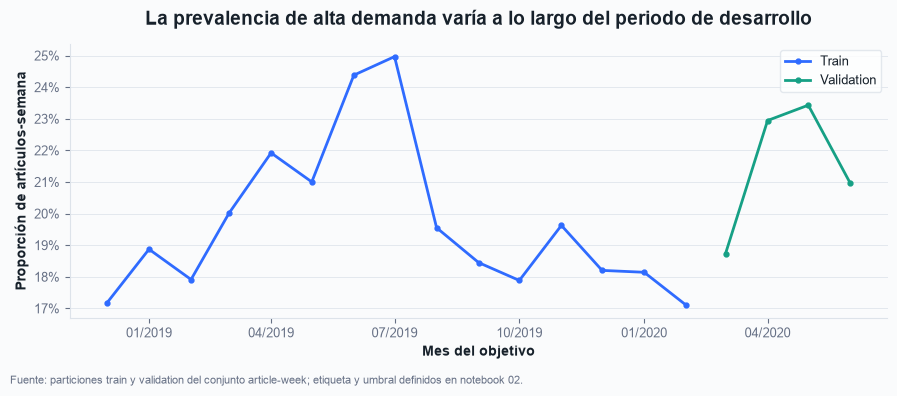

In [6]:
split_counts = model_data["split"].value_counts().rename_axis("partition").rename("rows")
prevalence_table = pd.DataFrame(
    {
        "rows": [len(train_all), len(validation_all)],
        "high_demand_prevalence": [train_all[TARGET].mean(), validation_all[TARGET].mean()],
        "first_target_week": [train_all["target_week"].min(), validation_all["target_week"].min()],
        "last_target_week": [train_all["target_week"].max(), validation_all["target_week"].max()],
    },
    index=["train", "validation"],
)
display(prevalence_table.assign(high_demand_prevalence=lambda table: table["high_demand_prevalence"].map("{:.1%}".format)))
display(split_counts.to_frame())
print(
    f"Definición heredada del notebook 02: ventas de la semana siguiente >= "
    f"{HIGH_DEMAND_THRESHOLD}; cuantíl de referencia: "
    f"{classification_definition.get('training_quantile', 'no registrado')}."
)

development_data = pd.concat([train_all, validation_all], ignore_index=True)
development_data["month"] = development_data["target_week"].dt.to_period("M").dt.to_timestamp()
monthly_prevalence = (
    development_data.groupby(["month", "split"], observed=True)[TARGET]
    .mean()
    .unstack("split")
)
fig, axis = plt.subplots(figsize=(9, 4.2))
for partition, color in [("train", BLUE), ("validation", TEAL)]:
    if partition in monthly_prevalence:
        axis.plot(
            monthly_prevalence.index,
            monthly_prevalence[partition],
            color=color,
            linewidth=2,
            marker="o",
            markersize=3.5,
            label=partition.capitalize(),
        )
axis.set_title("La prevalencia de alta demanda varía a lo largo del periodo de desarrollo", fontsize=14, fontweight="bold", pad=14)
axis.set_xlabel("Mes del objetivo", fontsize=10, fontweight="bold")
axis.set_ylabel("Proporción de artículos-semana", fontsize=10, fontweight="bold")
axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axis.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axis.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=9)
style_axis(axis)
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
add_source(fig, "Fuente: particiones train y validation del conjunto article-week; etiqueta y umbral definidos en notebook 02.")
plt.show()


## 2. Classification baselines

We use two reference points. The **training-prevalence baseline** assigns every validation row the positive-class prevalence observed in training; its class decision at 0.5 corresponds to the majority class. The **persistence-style baseline** predicts high demand when current-week sales already meet the same fixed unit threshold. Neither baseline learns from validation labels.


In [7]:
training_prevalence = float(y_train.mean())
baseline_probabilities = {
    "Training prevalence": np.full(len(y_validation), training_prevalence, dtype=float),
    "Current-sales rule": validation_sample["sales"].ge(HIGH_DEMAND_THRESHOLD).astype(float).to_numpy(),
}
baseline_results = []
for baseline_name, probabilities in baseline_probabilities.items():
    baseline_results.append(
        {"model": baseline_name, **classification_metrics(y_validation, probabilities)}
    )
baseline_metrics = pd.DataFrame(baseline_results).set_index("model")
display(baseline_metrics.round(3))
print(f"Train prevalence used by the baseline: {training_prevalence:.1%}")


,precision,recall,F1,PR-AUC,ROC-AUC,Brier
model,,,,,,
Training prevalence,0.000,0.000,0.000,0.213,0.500,0.168
Current-sales rule,0.782,0.813,0.797,0.676,0.876,0.088


Train prevalence used by the baseline: 19.9%


## 3. Preprocessing pipeline

Numerical predictors capture current and lagged sales, rolling demand, recent trend, prices, online-channel share, and cyclic week-of-year. Product type and broader product attributes are categorical. Identifiers, target values, split labels, and target-week fields are not predictors.

Imputation, scaling, and category encoding are fitted inside each model pipeline using training data only. Rare categories are grouped by the encoder and unseen validation categories are ignored safely. Sampling is stratified and reproducible; validation estimates represent the validation sample shown above.


In [8]:
def make_feature_frame(frame):
    features = frame.loc[:, FEATURES].copy()
    for column in CATEGORICAL_FEATURES:
        features[column] = features[column].fillna("Unknown").astype(str)
    return features

X_train = make_feature_frame(training_sample)
X_validation = make_feature_frame(validation_sample)

numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=25,
                max_categories=80,
                sparse_output=True,
            ),
        ),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    sparse_threshold=0.3,
)

for forbidden in {
    "article_id", "product_code", "target_next_week_sales", TARGET,
    "target_week", "split", "target_is_observed", "history_is_observed",
}:
    if forbidden in FEATURES:
        raise ValueError(f"Fuga de información: {forbidden} aparece entre los predictores.")

print(f"Predictores numéricos: {len(NUMERIC_FEATURES)}")
print(f"Predictores categóricos: {len(CATEGORICAL_FEATURES)}")
print(f"Filas usadas para ajuste: {len(X_train):,}; validación: {len(X_validation):,}")


Predictores numéricos: 18
Predictores categóricos: 6
Filas usadas para ajuste: 100,000; validación: 150,000


## 4. Candidate classifiers

We compare three distinct model families: regularized logistic regression, a shallow decision tree, and a Random Forest. Hyperparameters are deliberately moderate so the notebook remains usable on the full project dataset. All candidate pipelines share the same leakage-safe preprocessing and fixed random seed.


In [9]:
candidate_estimators = {
    "Logistic regression": LogisticRegression(
        C=1.0, solver="liblinear", max_iter=250, random_state=RANDOM_STATE
    ),
    "Decision tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=200, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=60, max_depth=14, min_samples_leaf=200,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

model_pipelines = {}
validation_probabilities = {}
model_results = []
scored_validation = validation_sample[
    ["target_week", "section_name", "sales", TARGET]
].reset_index(drop=True).copy()
scored_validation["month"] = scored_validation["target_week"].dt.strftime("%Y-%m")

for model_name, estimator in candidate_estimators.items():
    pipeline = Pipeline(
        [("preprocessor", clone(preprocessor)), ("classifier", estimator)]
    )
    started = perf_counter()
    pipeline.fit(X_train, y_train)
    elapsed_seconds = perf_counter() - started
    probabilities = pipeline.predict_proba(X_validation)[:, 1]
    model_pipelines[model_name] = pipeline
    validation_probabilities[model_name] = probabilities
    model_results.append(
        {
            "model": model_name,
            "fit_seconds": elapsed_seconds,
            **classification_metrics(y_validation, probabilities, threshold=0.5),
        }
    )
    print(f"{model_name}: ajuste terminado en {elapsed_seconds:.1f} s")


Logistic regression: ajuste terminado en 6.3 s
Decision tree: ajuste terminado en 6.7 s
Random forest: ajuste terminado en 3.3 s


## 5. Chronological validation metrics

The primary comparison metric is **Average Precision (PR-AUC)** because it focuses on positive-class retrieval when prevalence is below 50%. Precision, recall, and F1 are reported at the conventional 0.5 probability threshold; ROC-AUC and Brier score provide complementary discrimination and probability-quality context. Accuracy is intentionally not used to choose the model.

Monthly validation metrics show whether performance is stable across the held-out chronological period. Small monthly groups can be noisy, so they are interpreted alongside the pooled validation result and their sample sizes.


,precision,recall,F1,PR-AUC,ROC-AUC,Brier,fit_seconds
model,,,,,,,
Logistic regression,0.847,0.726,0.782,0.872,0.955,0.064,6.316
Decision tree,0.679,0.895,0.772,0.871,0.955,0.082,6.652
Random forest,0.658,0.890,0.756,0.842,0.947,0.091,3.261
Current-sales rule,0.782,0.813,0.797,0.676,0.876,0.088,NaN
Training prevalence,0.000,0.000,0.000,0.213,0.500,0.168,NaN


Selección provisional por PR-AUC de validation: Logistic regression


,model,month,n,PR-AUC,F1
0,Logistic regression,2020-03,51367,0.856,0.762
1,Logistic regression,2020-04,34245,0.869,0.788
2,Logistic regression,2020-05,40529,0.882,0.770
3,Logistic regression,2020-06,23859,0.911,0.828
4,Decision tree,2020-03,51367,0.850,0.746
5,Decision tree,2020-04,34245,0.860,0.761
6,Decision tree,2020-05,40529,0.883,0.798
7,Decision tree,2020-06,23859,0.914,0.794
8,Random forest,2020-03,51367,0.808,0.720
9,Random forest,2020-04,34245,0.825,0.750


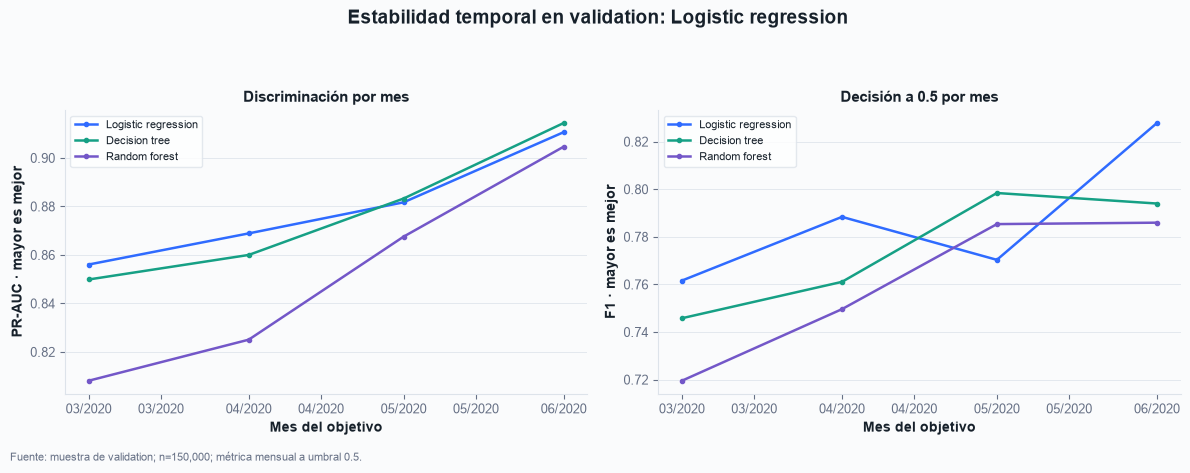

In [12]:
model_metrics = pd.DataFrame(model_results).set_index("model")
validation_metrics = pd.concat([baseline_metrics, model_metrics], axis=0)
validation_metrics = validation_metrics.sort_values("PR-AUC", ascending=False)
display(validation_metrics.round(3))

candidate_names = list(validation_probabilities)
selected_model = (
    validation_metrics.loc[candidate_names, "PR-AUC"]
    .sort_values(ascending=False)
    .index[0]
)
selected_probability = validation_probabilities[selected_model]
print(f"Selección provisional por PR-AUC de validation: {selected_model}")

monthly_rows = []
for model_name, probabilities in validation_probabilities.items():
    for month, positions in scored_validation.groupby("month", sort=True).indices.items():
        positions = np.asarray(positions)
        month_metrics = classification_metrics(
            y_validation.iloc[positions],
            probabilities[positions],
            threshold=0.5,
        )
        monthly_rows.append(
            {
                "model": model_name,
                "month": month,
                "n": len(positions),
                "PR-AUC": month_metrics["PR-AUC"],
                "F1": month_metrics["F1"],
            }
        )
monthly_metrics = pd.DataFrame(monthly_rows)
display(monthly_metrics.head(12).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for model_name in candidate_names:
    subset = monthly_metrics.loc[monthly_metrics["model"].eq(model_name)].copy()
    dates = pd.to_datetime(subset["month"])
    color = MODEL_COLORS[model_name]
    axes[0].plot(dates, subset["PR-AUC"], marker="o", linewidth=1.8, markersize=3, color=color, label=model_name)
    axes[1].plot(dates, subset["F1"], marker="o", linewidth=1.8, markersize=3, color=color, label=model_name)
for axis in axes:
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    axis.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=8))
    axis.set_xlabel("Mes del objetivo", fontsize=10, fontweight="bold")
    axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)
    style_axis(axis)
axes[0].set_title("Discriminación por mes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("PR-AUC · mayor es mejor", fontsize=10, fontweight="bold")
axes[1].set_title("Decisión a 0.5 por mes", fontsize=11, fontweight="bold")
axes[1].set_ylabel("F1 · mayor es mejor", fontsize=10, fontweight="bold")
fig.suptitle(f"Estabilidad temporal en validation: {selected_model}", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
add_source(fig, f"Fuente: muestra de validation; n={len(y_validation):,}; métrica mensual a umbral 0.5.")
plt.show()


## 6. Confusion matrix, ROC, Precision–Recall, and calibration

The following diagnostics use the provisionally selected model and the default probability threshold of 0.5. The precision–recall curve is foregrounded because the positive class is less prevalent; the ROC curve and calibration plot are complementary rather than standalone selection criteria.


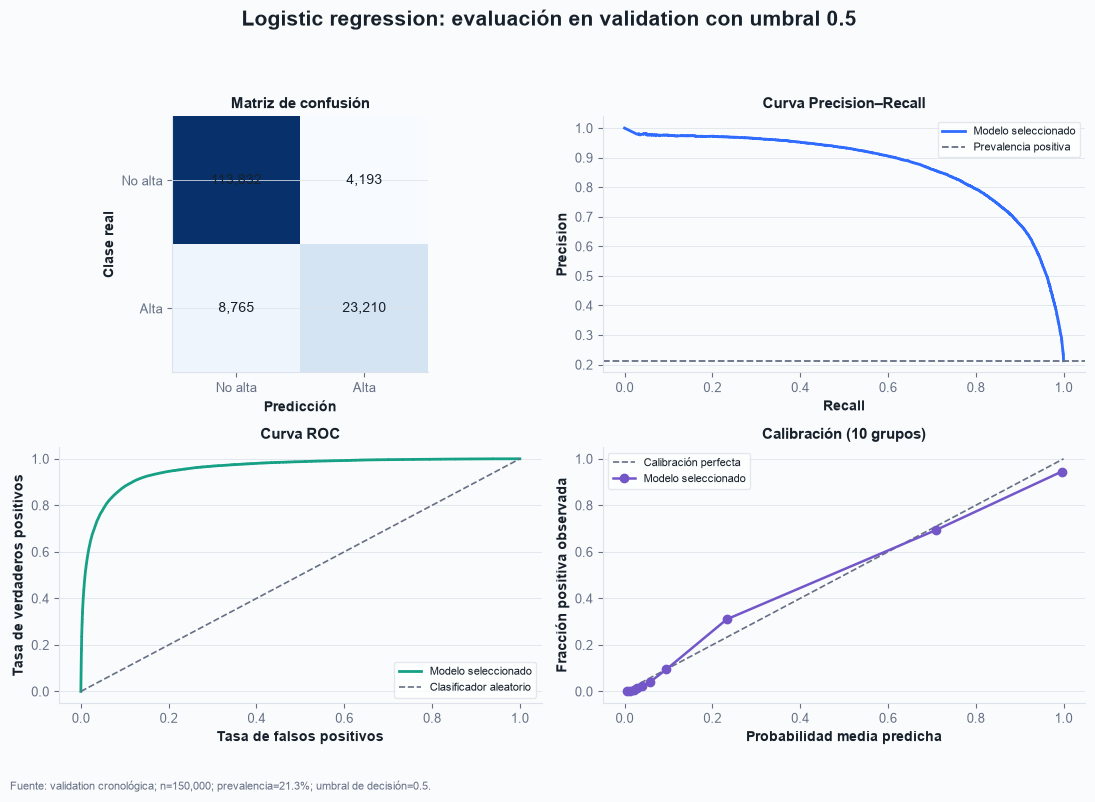

In [13]:
from sklearn.calibration import calibration_curve

default_prediction = (selected_probability >= 0.5).astype(int)
matrix = confusion_matrix(y_validation, default_prediction, labels=[0, 1])
precision_curve, recall_curve, _ = precision_recall_curve(y_validation, selected_probability)
false_positive_rate, true_positive_rate, _ = roc_curve(y_validation, selected_probability)
observed_fraction, mean_probability = calibration_curve(
    y_validation, selected_probability, n_bins=10, strategy="quantile"
)
validation_prevalence = float(y_validation.mean())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
fig.suptitle(
    f"{selected_model}: evaluación en validation con umbral 0.5",
    fontsize=15,
    fontweight="bold",
    y=0.99,
)

axis = axes[0, 0]
image = axis.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        axis.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center", color=INK, fontsize=10)
axis.set_xticks([0, 1], ["No alta", "Alta"])
axis.set_yticks([0, 1], ["No alta", "Alta"])
axis.set_xlabel("Predicción", fontsize=10, fontweight="bold")
axis.set_ylabel("Clase real", fontsize=10, fontweight="bold")
axis.set_title("Matriz de confusión", fontsize=11, fontweight="bold")

axis = axes[0, 1]
axis.plot(recall_curve, precision_curve, color=BLUE, linewidth=2, label="Modelo seleccionado")
axis.axhline(validation_prevalence, color=MUTED, linestyle="--", linewidth=1.3, label="Prevalencia positiva")
axis.set_xlabel("Recall", fontsize=10, fontweight="bold")
axis.set_ylabel("Precision", fontsize=10, fontweight="bold")
axis.set_title("Curva Precision–Recall", fontsize=11, fontweight="bold")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)

axis = axes[1, 0]
axis.plot(false_positive_rate, true_positive_rate, color=TEAL, linewidth=2, label="Modelo seleccionado")
axis.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Clasificador aleatorio")
axis.set_xlabel("Tasa de falsos positivos", fontsize=10, fontweight="bold")
axis.set_ylabel("Tasa de verdaderos positivos", fontsize=10, fontweight="bold")
axis.set_title("Curva ROC", fontsize=11, fontweight="bold")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)

axis = axes[1, 1]
axis.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Calibración perfecta")
axis.plot(mean_probability, observed_fraction, color=VIOLET, marker="o", linewidth=1.8, label="Modelo seleccionado")
axis.set_xlabel("Probabilidad media predicha", fontsize=10, fontweight="bold")
axis.set_ylabel("Fracción positiva observada", fontsize=10, fontweight="bold")
axis.set_title("Calibración (10 grupos)", fontsize=11, fontweight="bold")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)

for axis in axes.flat:
    style_axis(axis)
fig.tight_layout(rect=(0, 0.055, 1, 0.94))
add_source(
    fig,
    f"Fuente: validation cronológica; n={len(y_validation):,}; prevalencia={validation_prevalence:.1%}; umbral de decisión=0.5.",
)
plt.show()


## 7. Decision-threshold and business-error analysis

The probability decision threshold is separate from the fixed sales-unit threshold that defines high demand. We sweep decision thresholds on validation and choose the one with the highest validation F1; ties are resolved by higher precision and then the higher threshold. This is a transparent comparison rule, not a business-optimal policy: real inventory costs, margins, stock-outs, and replenishment constraints are unavailable here.

A false positive flags an article for high demand that does not meet the target definition; a false negative misses an article that does. Their operational costs can differ, so the threshold must be revisited when those costs are known.


,precision,recall,F1,Brier
Decision threshold 0.5,0.847,0.726,0.782,0.064
F1-optimal on validation (0.30),0.780,0.817,0.798,0.064


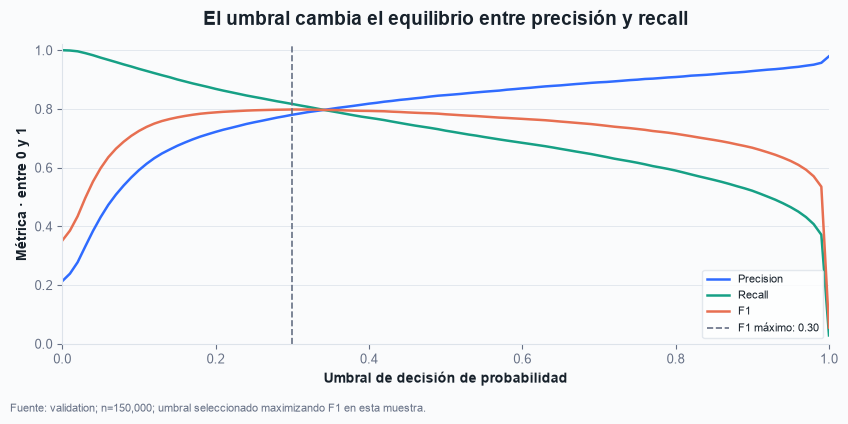

,count,interpretation
True negative,110665,"No alta demanda, predicha correctamente"
False positive,7360,Alerta de alta demanda sin positivo observado
False negative,5858,Alta demanda no detectada
True positive,26117,Alta demanda detectada


,n,positives,false_positives,actual_negatives,false_negatives,actual_positives,false_positive_rate,false_negative_rate
section_name,,,,,,,,
Womens Everyday Collection,16587,4692,928,11895,674,4692,0.078,0.144
Divided Collection,15675,3924,1223,11751,710,3924,0.104,0.181
Womens Lingerie,7915,3136,603,4779,418,3136,0.126,0.133
Womens Tailoring,7610,2420,509,5190,380,2420,0.098,0.157
"Womens Swimwear, beachwear",6447,2838,254,3609,271,2838,0.070,0.095
Womens Casual,5443,1610,284,3833,286,1610,0.074,0.178
Womens Small accessories,5214,738,300,4476,236,738,0.067,0.320
Womens Trend,4917,659,196,4258,236,659,0.046,0.358
H&M+,4293,921,273,3372,245,921,0.081,0.266


Las tasas por sección describen errores en la muestra de validación; no implican que la categoría cause el error.


In [14]:
threshold_rows = []
for decision_threshold in np.linspace(0, 1, 101):
    threshold_metrics = classification_metrics(
        y_validation,
        selected_probability,
        threshold=float(decision_threshold),
    )
    threshold_rows.append({"threshold": decision_threshold, **threshold_metrics})
threshold_sweep = pd.DataFrame(threshold_rows)
best_f1 = threshold_sweep["F1"].max()
best_candidates = threshold_sweep.loc[np.isclose(threshold_sweep["F1"], best_f1)]
best_threshold = float(
    best_candidates.sort_values(["precision", "threshold"], ascending=[False, False])
    .iloc[0]["threshold"]
)
best_threshold_metrics = classification_metrics(
    y_validation, selected_probability, threshold=best_threshold
)
default_threshold_metrics = classification_metrics(
    y_validation, selected_probability, threshold=0.5
)
threshold_comparison = pd.DataFrame(
    [default_threshold_metrics, best_threshold_metrics],
    index=["Decision threshold 0.5", f"F1-optimal on validation ({best_threshold:.2f})"],
)
display(threshold_comparison[["precision", "recall", "F1", "Brier"]].round(3))

fig, axis = plt.subplots(figsize=(8.5, 4.5))
for metric, color in [("precision", BLUE), ("recall", TEAL), ("F1", CORAL)]:
    axis.plot(threshold_sweep["threshold"], threshold_sweep[metric], color=color, linewidth=1.8, label=metric.capitalize())
axis.axvline(best_threshold, color=MUTED, linestyle="--", linewidth=1.2, label=f"F1 máximo: {best_threshold:.2f}")
axis.set_xlabel("Umbral de decisión de probabilidad", fontsize=10, fontweight="bold")
axis.set_ylabel("Métrica · entre 0 y 1", fontsize=10, fontweight="bold")
axis.set_title("El umbral cambia el equilibrio entre precisión y recall", fontsize=14, fontweight="bold", pad=14)
axis.set_xlim(0, 1)
axis.set_ylim(0, 1.02)
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)
style_axis(axis)
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
add_source(fig, f"Fuente: validation; n={len(y_validation):,}; umbral seleccionado maximizando F1 en esta muestra.")
plt.show()

prediction_at_best = (selected_probability >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_validation, prediction_at_best, labels=[0, 1]).ravel()
error_summary = pd.DataFrame(
    {
        "count": [tn, fp, fn, tp],
        "interpretation": [
            "No alta demanda, predicha correctamente",
            "Alerta de alta demanda sin positivo observado",
            "Alta demanda no detectada",
            "Alta demanda detectada",
        ],
    },
    index=["True negative", "False positive", "False negative", "True positive"],
)
display(error_summary)

segment_errors = scored_validation[["section_name", TARGET]].copy()
segment_errors["prediction"] = prediction_at_best
segment_errors["false_positive"] = (
    segment_errors["prediction"].eq(1) & segment_errors[TARGET].eq(0)
).astype(int)
segment_errors["actual_negative"] = segment_errors[TARGET].eq(0).astype(int)
segment_errors["false_negative"] = (
    segment_errors["prediction"].eq(0) & segment_errors[TARGET].eq(1)
).astype(int)
segment_errors["actual_positive"] = segment_errors[TARGET].eq(1).astype(int)
segment_summary = (
    segment_errors.groupby("section_name", dropna=False)
    .agg(
        n=(TARGET, "size"),
        positives=(TARGET, "sum"),
        false_positives=("false_positive", "sum"),
        actual_negatives=("actual_negative", "sum"),
        false_negatives=("false_negative", "sum"),
        actual_positives=("actual_positive", "sum"),
    )
)
segment_summary["false_positive_rate"] = (
    segment_summary["false_positives"] / segment_summary["actual_negatives"].replace(0, np.nan)
)
segment_summary["false_negative_rate"] = (
    segment_summary["false_negatives"] / segment_summary["actual_positives"].replace(0, np.nan)
)
display(segment_summary.sort_values("n", ascending=False).head(12).round(3))
print(
    "Las tasas por sección describen errores en la muestra de validación; "
    "no implican que la categoría cause el error."
)


## 8. Model selection and limitations

The candidate is selected by the highest pooled PR-AUC on the chronological validation sample; its probability threshold is selected separately by validation F1. Neither choice uses the final test partition. After the feature set, model, and decision policy are frozen, the project may perform a single independent test evaluation in a later, explicitly controlled step.

### Interpretation and limitations

- The label represents **recorded sales**, not latent demand; stock availability and unmet demand are not observed.
- The candidate population includes articles sold in the current week, so results do not directly cover new or inactive articles.
- Training and validation are capped, stratified samples for iteration. Small segment and monthly groups can have unstable metrics.
- The threshold optimizes F1, not inventory profit or service level. False-positive and false-negative costs are not available.
- Calibration and performance may drift across weeks and product groups; monthly and section-level results are descriptive.
- Product associations are predictive, not causal. No final-test result is reported here.

Re-run from the first cell after changing the current data publication or model setup. Record the run identifier, sample limits, random seed, predictors, hyperparameters, and validation metrics when comparing experiments.


In [15]:
selection_summary = pd.Series(
    {
        "selected_model": selected_model,
        "selection_metric": "PR-AUC on chronological validation",
        "validation_PR_AUC": classification_metrics(
            y_validation, selected_probability
        )["PR-AUC"],
        "validation_F1_at_0.5": default_threshold_metrics["F1"],
        "decision_threshold_selected_on_validation": best_threshold,
        "validation_F1_at_selected_threshold": best_threshold_metrics["F1"],
        "validation_sample_rows": len(y_validation),
        "train_sample_rows": len(y_train),
        "high_demand_sales_threshold": HIGH_DEMAND_THRESHOLD,
        "final_test_used": False,
    },
    name="value",
)
display(selection_summary.to_frame())
display(validation_metrics.round(3))


,value
selected_model,Logistic regression
selection_metric,PR-AUC on chronological validation
validation_PR_AUC,0.871915
validation_F1_at_0.5,0.781771
decision_threshold_selected_on_validation,0.3
validation_F1_at_selected_threshold,0.79805
validation_sample_rows,150000
train_sample_rows,100000
high_demand_sales_threshold,16
final_test_used,False


,precision,recall,F1,PR-AUC,ROC-AUC,Brier,fit_seconds
model,,,,,,,
Logistic regression,0.847,0.726,0.782,0.872,0.955,0.064,6.316
Decision tree,0.679,0.895,0.772,0.871,0.955,0.082,6.652
Random forest,0.658,0.890,0.756,0.842,0.947,0.091,3.261
Current-sales rule,0.782,0.813,0.797,0.676,0.876,0.088,NaN
Training prevalence,0.000,0.000,0.000,0.213,0.500,0.168,NaN
